In [14]:
%pip install scikeras

Note: you may need to restart the kernel to use updated packages.


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scikeras.wrappers import KerasClassifier

np.random.seed(42)
tf.random.set_seed(42)

In [2]:
df = pd.read_csv(r"C:\Users\deytu\Desktop\study\EXCELR\Assignment\Data and Docs\sonardataset.csv")
df

,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,x_10,...,x_52,x_53,x_54,x_55,x_56,x_57,x_58,x_59,x_60,Y
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203,0.0187,0.0346,0.0168,0.0177,0.0393,0.1630,0.2028,0.1694,0.2328,0.2684,...,0.0116,0.0098,0.0199,0.0033,0.0101,0.0065,0.0115,0.0193,0.0157,M
204,0.0323,0.0101,0.0298,0.0564,0.0760,0.0958,0.0990,0.1018,0.1030,0.2154,...,0.0061,0.0093,0.0135,0.0063,0.0063,0.0034,0.0032,0.0062,0.0067,M
205,0.0522,0.0437,0.0180,0.0292,0.0351,0.1171,0.1257,0.1178,0.1258,0.2529,...,0.0160,0.0029,0.0051,0.0062,0.0089,0.0140,0.0138,0.0077,0.0031,M
206,0.0303,0.0353,0.0490,0.0608,0.0167,0.1354,0.1465,0.1123,0.1945,0.2354,...,0.0086,0.0046,0.0126,0.0036,0.0035,0.0034,0.0079,0.0036,0.0048,M


In [3]:
print("Dataset shape:", df.shape)
display(df.head())
print(df.info())
print(df.isnull().sum().sum(), "missing values")

Dataset shape: (208, 61)


,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,x_10,...,x_52,x_53,x_54,x_55,x_56,x_57,x_58,x_59,x_60,Y
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 61 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x_1     208 non-null    float64
 1   x_2     208 non-null    float64
 2   x_3     208 non-null    float64
 3   x_4     208 non-null    float64
 4   x_5     208 non-null    float64
 5   x_6     208 non-null    float64
 6   x_7     208 non-null    float64
 7   x_8     208 non-null    float64
 8   x_9     208 non-null    float64
 9   x_10    208 non-null    float64
 10  x_11    208 non-null    float64
 11  x_12    208 non-null    float64
 12  x_13    208 non-null    float64
 13  x_14    208 non-null    float64
 14  x_15    208 non-null    float64
 15  x_16    208 non-null    float64
 16  x_17    208 non-null    float64
 17  x_18    208 non-null    float64
 18  x_19    208 non-null    float64
 19  x_20    208 non-null    float64
 20  x_21    208 non-null    float64
 21  x_22    208 non-null    float64
 22  x_

In [4]:
print(df["Y"].value_counts())

Y
M    111
R     97
Name: count, dtype: int64


In [5]:
print(df["Y"].value_counts(normalize=True) * 100)

Y
M    53.365385
R    46.634615
Name: proportion, dtype: float64


In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
x_1,208.0,0.029164,0.022991,0.0015,0.013350,0.02280,0.035550,0.1371
x_2,208.0,0.038437,0.032960,0.0006,0.016450,0.03080,0.047950,0.2339
x_3,208.0,0.043832,0.038428,0.0015,0.018950,0.03430,0.057950,0.3059
x_4,208.0,0.053892,0.046528,0.0058,0.024375,0.04405,0.064500,0.4264
x_5,208.0,0.075202,0.055552,0.0067,0.038050,0.06250,0.100275,0.4010
x_6,208.0,0.104570,0.059105,0.0102,0.067025,0.09215,0.134125,0.3823
x_7,208.0,0.121747,0.061788,0.0033,0.080900,0.10695,0.154000,0.3729
x_8,208.0,0.134799,0.085152,0.0055,0.080425,0.11210,0.169600,0.4590
x_9,208.0,0.178003,0.118387,0.0075,0.097025,0.15225,0.233425,0.6828
x_10,208.0,0.208259,0.134416,0.0113,0.111275,0.18240,0.268700,0.7106


In [8]:
X = df.drop("Y", axis=1)
y = df["Y"].map({"R": 0, "M": 1})

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (208, 60)
y shape: (208,)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (166, 60)
Testing set: (42, 60)


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Observation

- The dataset contains **208 observations** and **60 numerical input features** along with one target variable (`Y`).
- The target variable represents two classes: **Mine (M)** and **Rock (R)**.
- All 60 predictor variables are of **float64** data type, while the target variable is categorical (`object`).
- The dataset contains **0 missing values**, indicating that no missing-value treatment is required.
- The features represent sonar signal energy measurements across different frequency bands.
- Since the features may have different scales, **standardization using StandardScaler** is applied before training the ANN model.
- An **80:20 stratified train-test split** is used to maintain a similar class distribution in both datasets.
- Overall, the dataset is clean and suitable for building a binary classification model using an Artificial Neural Network.

In [11]:
def build_default_model():
    model = keras.Sequential([
        keras.Input(shape=(60,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [16]:
default_model = build_default_model()

history = default_model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.4545 - loss: 0.8129 - val_accuracy: 0.3824 - val_loss: 0.8773
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5682 - loss: 0.7277 - val_accuracy: 0.4118 - val_loss: 0.7969
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6742 - loss: 0.6655 - val_accuracy: 0.4412 - val_loss: 0.7284
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7045 - loss: 0.6173 - val_accuracy: 0.5294 - val_loss: 0.6722
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7500 - loss: 0.5797 - val_accuracy: 0.5588 - val_loss: 0.6268
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7576 - loss: 0.5488 - val_accuracy: 0.5882 - val_loss: 0.5902
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7576 - loss: 0.5221 - val_accuracy: 0.6765 - val_loss: 0.5601
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7727 - loss: 0.4985 - val_accuracy: 0.6765 - val_loss: 0.5353

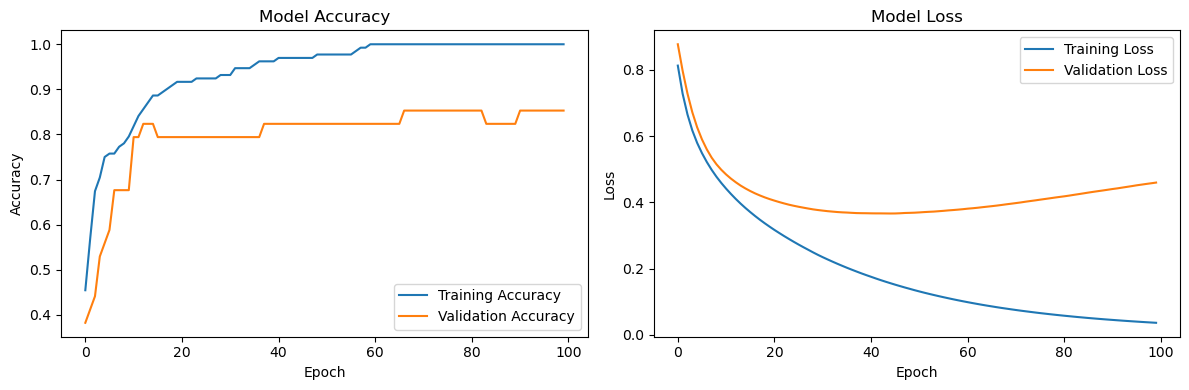

In [17]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
y_prob_default = default_model.predict(X_test_scaled, verbose=0).ravel()
y_pred_default = (y_prob_default >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred_default,
    labels=[0, 1],
    target_names=["Rock", "Mine"],
    zero_division=0
))

              precision    recall  f1-score   support

        Rock       0.95      0.95      0.95        20
        Mine       0.95      0.95      0.95        22

    accuracy                           0.95        42
   macro avg       0.95      0.95      0.95        42
weighted avg       0.95      0.95      0.95        42



### Observation

- The ANN model achieved an overall **accuracy of 95%** on the test set.
- Both **Rock** and **Mine** classes achieved a **precision of 0.95, recall of 0.95, and F1-score of 0.95**.
- The model correctly classified the majority of the **42 test observations**, with balanced performance across both classes.
- The equal precision and recall values indicate that the model performed consistently in identifying both rocks and mines.
- The **macro average and weighted average F1-score of 0.95** further indicate balanced classification performance.
- Overall, the baseline ANN demonstrates strong performance on the test dataset for distinguishing between **Mine** and **Rock** sonar signals.

In [20]:
default_results = {
    "Model": "Default ANN",
    "Accuracy": accuracy_score(y_test, y_pred_default),
    "Precision": precision_score(y_test, y_pred_default, zero_division=0),
    "Recall": recall_score(y_test, y_pred_default, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_default, zero_division=0)
}

default_results

{'Model': 'Default ANN',
 'Accuracy': 0.9523809523809523,
 'Precision': 0.9545454545454546,
 'Recall': 0.9545454545454546,
 'F1-score': 0.9545454545454546}

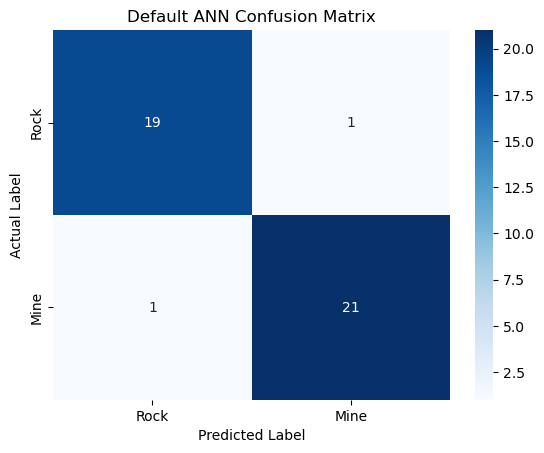

In [21]:
cm = confusion_matrix(y_test, y_pred_default, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rock", "Mine"],
    yticklabels=["Rock", "Mine"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Default ANN Confusion Matrix")
plt.show()

In [22]:
#### Hyper parametertuning
def build_tuned_model(
    hidden_layers=1,
    neurons=16,
    activation="relu",
    learning_rate=0.001
):
    model = keras.Sequential()
    model.add(keras.Input(shape=(60,)))

    for _ in range(hidden_layers):
        model.add(layers.Dense(neurons, activation=activation))

    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [23]:
ann = KerasClassifier(
    model=build_tuned_model,
    epochs=60,
    verbose=0,
    random_state=42
)

param_grid = {
    "model__hidden_layers": [1, 2],
    "model__neurons": [16, 32],
    "model__activation": ["relu", "tanh"],
    "model__learning_rate": [0.001, 0.01],
    "batch_size": [16, 32]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid = GridSearchCV(
    estimator=ann,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=1,
    refit=True
)

grid.fit(X_train_scaled, y_train)

,estimator,KerasClassifi..._weight=None )
,param_grid,"{'batch_size': [16, 32], 'model__activation': ['relu', 'tanh'], 'model__hidden_layers': [1, 2], 'model__learning_rate': [0.001, 0.01], ...}"
,scoring,'f1'
,n_jobs,1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,model,<function bui...0022F626D7560>


In [24]:
print("Best Parameters:")
print(grid.best_params_)

print("\nBest Cross-Validation F1-score:")
print(grid.best_score_)

Best Parameters:
{'batch_size': 32, 'model__activation': 'tanh', 'model__hidden_layers': 1, 'model__learning_rate': 0.01, 'model__neurons': 32}

Best Cross-Validation F1-score:
0.851181367043436


In [25]:
tuned_model = grid.best_estimator_

y_pred_tuned = tuned_model.predict(X_test_scaled).astype(int).ravel()

tuned_results = {
    "Model": "Tuned ANN",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision": precision_score(y_test, y_pred_tuned, zero_division=0),
    "Recall": recall_score(y_test, y_pred_tuned, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_tuned, zero_division=0)
}

print(classification_report(
    y_test,
    y_pred_tuned,
    labels=[0, 1],
    target_names=["Rock", "Mine"],
    zero_division=0
))

              precision    recall  f1-score   support

        Rock       0.85      0.85      0.85        20
        Mine       0.86      0.86      0.86        22

    accuracy                           0.86        42
   macro avg       0.86      0.86      0.86        42
weighted avg       0.86      0.86      0.86        42



### Observation – Tuned ANN Model

- The tuned ANN achieved an overall **accuracy of 86%** on the test set.
- The **Rock** class achieved a precision, recall, and F1-score of **0.85**.
- The **Mine** class achieved a precision, recall, and F1-score of **0.86**.
- The **macro average and weighted average F1-score were both 0.86**, indicating relatively balanced performance across the two classes.
- Compared with the baseline ANN accuracy of **95%**, the tuned model achieved lower performance on this particular test set.
- Although the hyperparameter search selected the tuned configuration based on cross-validation performance, the results show that the selected configuration **did not improve test-set performance** for this split.
- This difference highlights the importance of evaluating hyperparameter-tuned models on an **unseen test set** rather than relying only on cross-validation results.

In [26]:
comparison = pd.DataFrame([
    default_results,
    tuned_results
])

display(
    comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-score
0,Default ANN,0.9524,0.9545,0.9545,0.9545
1,Tuned ANN,0.8571,0.8636,0.8636,0.8636


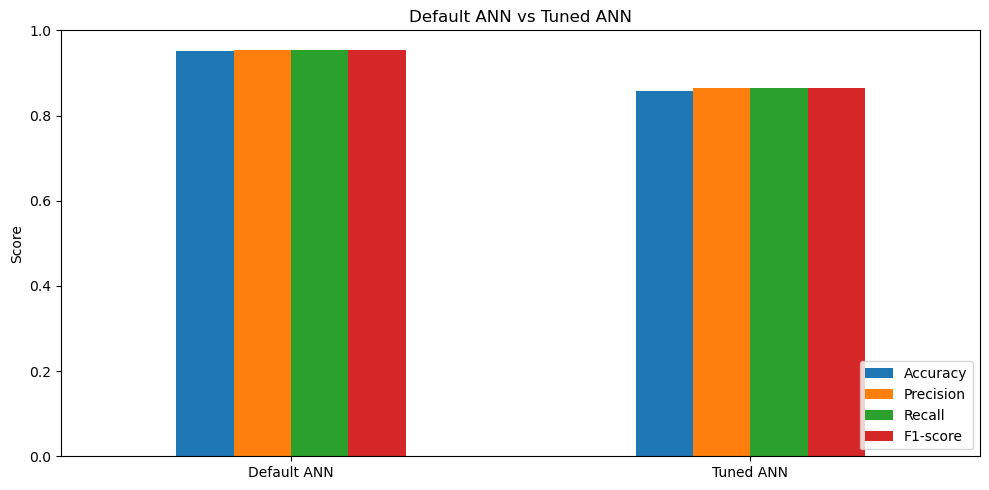

In [27]:
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Default ANN vs Tuned ANN")
plt.ylabel("Score")
plt.xlabel("")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Model Comparison Observation

- The **Default ANN** achieved an accuracy of **95.24%**, while the **Tuned ANN** achieved **85.71%** on the test set.
- The Default ANN also recorded higher **precision, recall, and F1-score (95.45%)** compared with the Tuned ANN (**86.36%**).
- Although hyperparameter tuning produced a configuration with the highest cross-validation F1-score, it did **not improve performance on the unseen test set**.
- The decrease in performance may be influenced by the **small dataset size (208 observations)** and the sensitivity of ANN models to different data splits and hyperparameter configurations.
- Therefore, for this particular train-test split, the **Default ANN demonstrated stronger test-set performance** than the Tuned ANN.
- These results show that hyperparameter tuning does not necessarily guarantee better generalization performance, particularly when working with a small dataset.

### Conclusion

The SONAR classification problem was successfully addressed using an Artificial Neural Network to distinguish between **Mine** and **Rock** signals. The dataset contained 208 observations with 60 numerical sonar features and no missing values. The features were standardized before training, and the data was divided using a stratified 80:20 train-test split.

The **Default ANN** achieved an accuracy of **95.24%**, with precision, recall, and F1-score of **95.45%**. Hyperparameter tuning was performed by varying the number of hidden layers, neurons, activation function, learning rate, and batch size. Although the tuned configuration achieved the best cross-validation F1-score of **0.8512**, its test accuracy was **85.71%**, which was lower than the default model.

The results demonstrate that hyperparameter tuning does not always lead to better performance on unseen data, particularly when working with a small dataset. For this particular train-test split, the **Default ANN provided better test-set performance**. Further validation using different train-test splits or larger independent datasets would be useful to assess the model's generalization and reliability.